# 🛒 Analyzing Ecommerce Orders Data

Notebook construit à partir du script `ecommerce_orders_analysis.py`.

- **@author** Alex Alkhatib


In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Set the working directory
# Dans le script original, le chemin était codé en dur :
# os.chdir('C:/Users/anasa/Downloads/Python for Data Analysis/Project 2 - Analyzing Ecommerce Orders Data')
# Ici on se place dans le dossier du notebook, où se trouvent les fichiers .xlsx
os.chdir(os.path.dirname(os.path.abspath('ecommerce_orders_analysis.ipynb')))

# Check the current working directory
print(os.getcwd())

C:\Users\anasa\Downloads\Portfolio\ecommerce-orders-analysis-main


## Loading Files

In [3]:
# Load the orders data

orders_data = pd.read_excel('orders.xlsx')

# Load the payments data
# if it's a csv file you would use pd.read_csv('filename.csv')
payments_data = pd.read_excel('order_payment.xlsx')

# Load the customers data

customers_data = pd.read_excel('customers.xlsx')

## Describing the data

In [4]:
orders_data.info()
payments_data.info()
customers_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99444 entries, 0 to 99443
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99444 non-null  object        
 1   customer_id                    99444 non-null  object        
 2   order_status                   99444 non-null  object        
 3   order_purchase_timestamp       99444 non-null  datetime64[ns]
 4   order_approved_at              99284 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97661 non-null  datetime64[ns]
 6   order_delivered_customer_date  96479 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99444 non-null  datetime64[ns]
dtypes: datetime64[ns](5), object(3)
memory usage: 6.1+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103887 entries, 0 to 103886
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
-

In [5]:
# Handling missing data

# Check for missing data in the orders data

orders_data.isnull().sum()
payments_data.isnull().sum()
customers_data.isnull().sum()

# Filling in the missing values in orders data with a default value
orders_data2 = orders_data.fillna('N/A')
# Check if there are null values in orders_data2
orders_data2.isnull().sum()

# Drop rows with missing values in payments data
payments_data = payments_data.dropna()
# Check if there are null values in payments_data
payments_data.isnull().sum()

order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

## Removing Duplicate Data

In [6]:
# Check for duplicates in our orders data
orders_data.duplicated().sum()

# Remove duplicates from orders data
orders_data = orders_data.drop_duplicates()

# Check for duplicates in our payments data
payments_data.duplicated().sum()

# Remove duplicates from payments data
payments_data = payments_data.drop_duplicates()

## Filtering the Data

In [7]:
# Select a subset of the orders data based on the order status
invoiced_orders_data = orders_data[orders_data['order_status'] == 'invoiced']
#reset the index
invoiced_orders_data = invoiced_orders_data.reset_index(drop=True)

# Select a subset of the payments data where payment type = Credit Card and payment value > 1000
credit_card_payments_data = payments_data[
    (payments_data['payment_type'] == 'credit_card') & 
    (payments_data['payment_value'] > 1000)
    ]

# Select a subset of customers based on customer state = SP
customers_data_state = customers_data[customers_data['customer_state'] == 'SP']

## Merge and Join Dataframes

In [8]:
# Merge orders data with payments data on order_id column
merged_data = pd.merge(orders_data, payments_data, on='order_id')

# Join the merged data with our customers data on the customer_id column
joined_data = pd.merge(merged_data, customers_data, on='customer_id')

## Data Visualization

In [9]:
# Create a field called month_year from order_purchase_timestamp
joined_data['month_year'] = joined_data['order_purchase_timestamp'].dt.to_period('M')
joined_data['week_year'] = joined_data['order_purchase_timestamp'].dt.to_period('W')
joined_data['year'] = joined_data['order_purchase_timestamp'].dt.to_period('Y')

grouped_data = joined_data.groupby('month_year')['payment_value'].sum()
grouped_data = grouped_data.reset_index()

#convert month_year from period into string
grouped_data['month_year'] = grouped_data['month_year'].astype(str)

(array([-200000.,       0.,  200000.,  400000.,  600000.,  800000.,
        1000000., 1200000., 1400000.]),
 [Text(0, -200000.0, '−200000'),
  Text(0, 0.0, '0'),
  Text(0, 200000.0, '200000'),
  Text(0, 400000.0, '400000'),
  Text(0, 600000.0, '600000'),
  Text(0, 800000.0, '800000'),
  Text(0, 1000000.0, '1000000'),
  Text(0, 1200000.0, '1200000'),
  Text(0, 1400000.0, '1400000')])

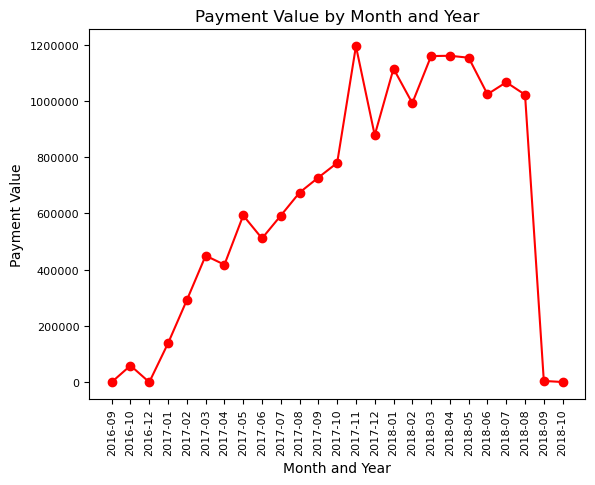

In [10]:
#creating a plot

plt.plot(grouped_data['month_year'], grouped_data['payment_value'], color='red', marker='o')
plt.ticklabel_format(useOffset=False, style='plain', axis='y')
plt.xlabel('Month and Year')
plt.ylabel('Payment Value')
plt.title('Payment Value by Month and Year')
plt.xticks(rotation = 90, fontsize=8)
plt.yticks(fontsize=8)

### Scatter Plot

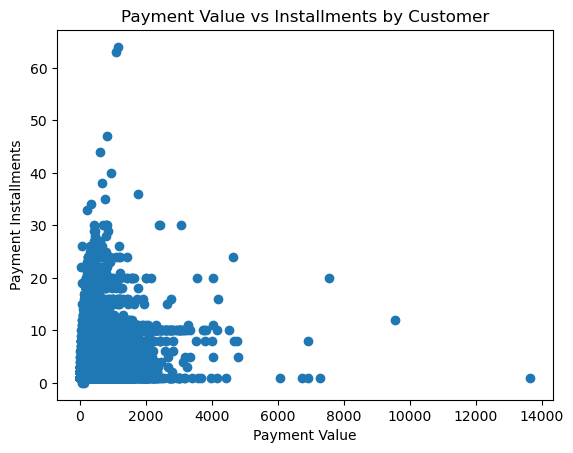

In [11]:
# create the DataFrame
scatter_df = joined_data.groupby('customer_unique_id').agg({'payment_value' : 'sum', 'payment_installments' : 'sum'})

plt.scatter(scatter_df['payment_value'], scatter_df['payment_installments'])
plt.xlabel('Payment Value')
plt.ylabel('Payment Installments')
plt.title('Payment Value vs Installments by Customer')
plt.show()

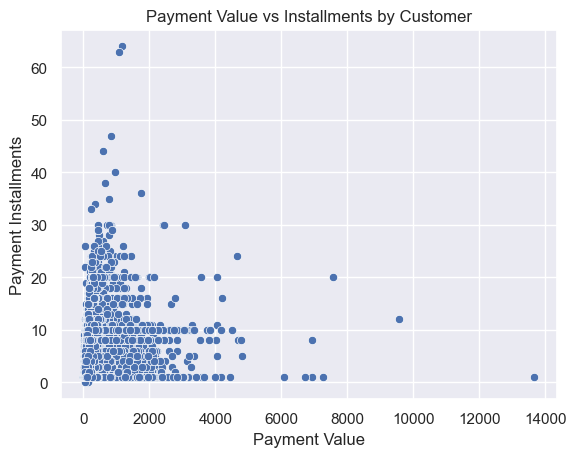

In [12]:
# Using seaborn to create a scatterplot

sns.set_theme(style='darkgrid') #whitegrid, darkgrid, dark, white

sns.scatterplot(data=scatter_df, x='payment_value', y='payment_installments')
plt.xlabel('Payment Value')
plt.ylabel('Payment Installments')
plt.title('Payment Value vs Installments by Customer')
plt.show()

### Creating a bar chart

Text(0.5, 1.0, 'Payment per Payment Type by Month')

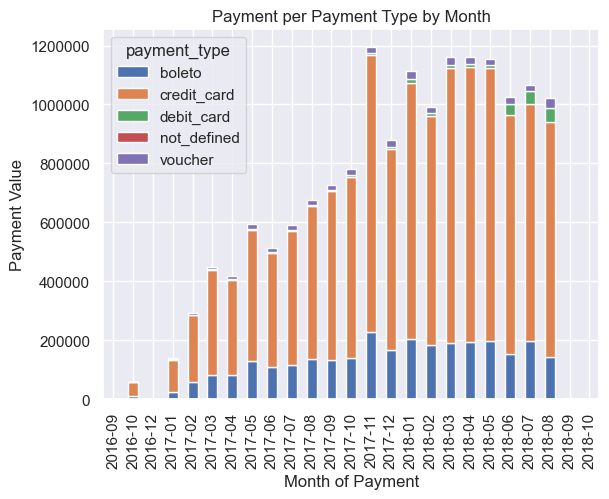

In [13]:
bar_chart_df = joined_data.groupby(['payment_type', 'month_year'])['payment_value'].sum()
bar_chart_df = bar_chart_df.reset_index()

pivot_data = bar_chart_df.pivot(index='month_year', columns='payment_type', values='payment_value')

pivot_data.plot(kind='bar', stacked='True')
plt.ticklabel_format(useOffset=False, style='plain', axis='y')
plt.xlabel('Month of Payment')
plt.ylabel('Payment Value')
plt.title('Payment per Payment Type by Month')

### Creating a box plot

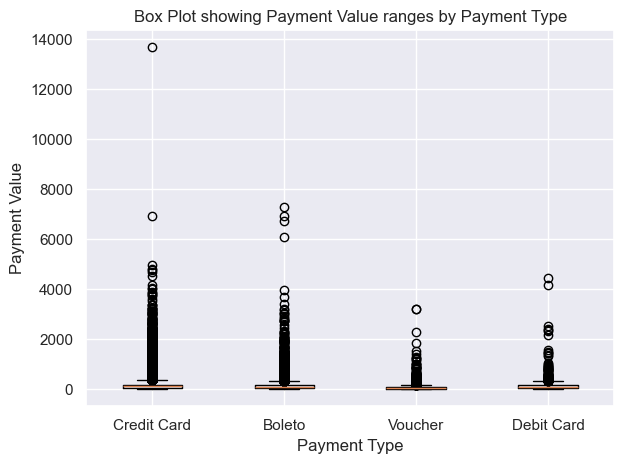

In [14]:
payment_values = joined_data['payment_value']
payment_types = joined_data['payment_type']

# creating a separate box plot per payment type
plt.boxplot([ payment_values[payment_types == 'credit_card'],
             payment_values[payment_types == 'boleto'],
             payment_values[payment_types == 'voucher'],
             payment_values[payment_types == 'debit_card']],
             labels = ['Credit Card', 'Boleto', 'Voucher', 'Debit Card']  
            )

# set labels and titles

plt.xlabel('Payment Type')
plt.ylabel('Payment Value')
plt.title('Box Plot showing Payment Value ranges by Payment Type')
plt.tight_layout()

plt.show()

### Creating a subplot (3 plots in one)

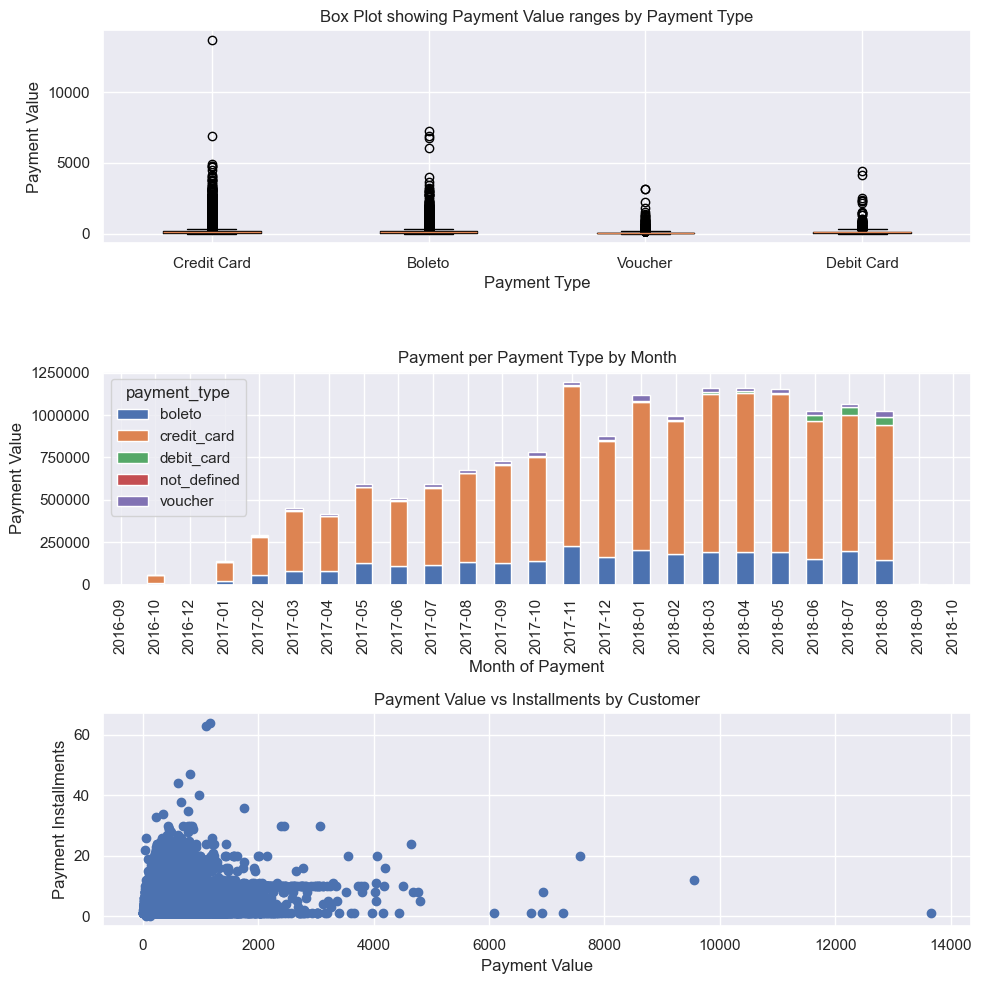

In [15]:
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10,10))

# ax which is boxplot

ax1.boxplot([ payment_values[payment_types == 'credit_card'],
             payment_values[payment_types == 'boleto'],
             payment_values[payment_types == 'voucher'],
             payment_values[payment_types == 'debit_card']],
             labels = ['Credit Card', 'Boleto', 'Voucher', 'Debit Card']  
            )

# set labels and titles

ax1.set_xlabel('Payment Type')
ax1.set_ylabel('Payment Value')
ax1.set_title('Box Plot showing Payment Value ranges by Payment Type')

# ax2 is the stacked bar chart 

pivot_data.plot(kind='bar', stacked='True', ax=ax2)
ax2.ticklabel_format(useOffset=False, style='plain', axis='y')

# set labels and titles
ax2.set_xlabel('Month of Payment')
ax2.set_ylabel('Payment Value')
ax2.set_title('Payment per Payment Type by Month')

# ax3 is a scatterplot

ax3.scatter(scatter_df['payment_value'], scatter_df['payment_installments'])

# set labels and titles
ax3.set_xlabel('Payment Value')
ax3.set_ylabel('Payment Installments')
ax3.set_title('Payment Value vs Installments by Customer')

fig.tight_layout()

plt.savefig('my_plot.png')